## モジュール

In [70]:
import numpy as np
import pandas as pd
import math
import base64
import bokeh
import matplotlib.pyplot as plt
import xgboost as xgb
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from rdkit import rdBase, Chem
from rdkit.Chem import AllChem, PandasTools, rdFingerprintGenerator, rdMolDescriptors, rdmolops, Descriptors, Draw, EState, rdMolTransforms
from rdkit.Chem.Fragments import fr_Al_COO, fr_C_O_noCOO, fr_allylic_oxid, fr_aryl_methyl, fr_ester
from rdkit.Chem.rdmolops import GetDistanceMatrix
from io import BytesIO
from bokeh.io import output_notebook, show, save
from bokeh.plotting import figure, show
from bokeh.models import ColumnDataSource, HoverTool, Range1d, Span
from bokeh.transform import factor_cmap
output_notebook()

Loading BokehJS ...

## データ読み込み

In [71]:
# データの読み込み
# df_data = pd.read_csv("../Dataset/train_Classification.csv", encoding="cp1252")
# df_test = pd.read_csv("../Dataset/test_Classification.csv", encoding="cp1252")

# df_data = pd.read_csv("../data/train_Classification.csv")
df_data = pd.read_csv("../data/train_multiClassification_data.csv", encoding="cp932")
df_test = pd.read_csv("../data/test_multiClassification_data.csv", encoding="cp932")

# df_data = df_data[df_data["MolWt"] < 500].reset_index(drop=True)
df_test = df_test[df_test["MolWt"] < 500].reset_index(drop=True)

# df_data = df_data[df_data["MolLogP"] < 5].reset_index(drop=True)
df_test = df_test[df_test["MolLogP"] < 5].reset_index(drop=True)
# df_data = df_data[df_data["MolLogP"] > -2].reset_index(drop=True)
df_test = df_test[df_test["MolLogP"] > -2].reset_index(drop=True)

# 欠損値のある行で特定のものを削除する
# df_data = df_data[df_data['fr_phenol'] > 0].reset_index(drop=True)
# df_test = df_test[df_test['fr_phenol'] > 0].reset_index(drop=True)

In [72]:
PandasTools.AddMoleculeColumnToFrame(df_data, "iso_SMILES")
PandasTools.AddMoleculeColumnToFrame(df_test, "iso_SMILES")
df_data = df_data.fillna(value={"ROMol": 0})
df_test = df_test.fillna(value={"ROMol": 0})

/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/rdkit/Chem/PandasTools.py:381: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame[molCol] = frame[smilesCol].map(Chem.MolFromSmiles)
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/rdkit/Chem/PandasTools.py:381: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  frame[molCol] = frame[smilesCol].map(Chem.MolFromSmiles)


In [73]:
df_data2 = df_data[["assay_multiclass"]]
df_data3 = df_data[["iso_SMILES", "ROMol"]]
# df_data1 = df_data[['SMR_VSA9', 'AATSC4c', 'Mor20m', 'Mor13m', 'ATSC4dv', 'MaxPartialCharge', 'E_HOMO_PubChemQC', 'MaxAbsPartialCharge', 'Mor19m', 'Mor15', 'E_LUMO_PubChemQC', 'GATS1are', 'AATSC3c', 'SlogP_VSA11', 'ATSC7dv', 'BCUT2D_LOGPHI', 'Mor13', 'Mor16p', 'Mor18m', 'GATS1dv', 'ATSC4c', 'MinAbsPartialCharge']]
# df_data1 = df_data[['SMR_VSA9', 'AATSC4c', 'Mor20m', 'Mor13m', 'E_LUMO_calc', 'ATSC4dv', 'MaxPartialCharge', 'E_HOMO_calc', 'MaxAbsEStateIndex', 'MaxAbsPartialCharge', 'Mor19m', 'GATS4dv', 'Mor15', 'GATS1are', 'AATSC3c', 'VSA_EState5', 'SlogP_VSA11', 'ATSC7dv', 'BCUT2D_LOGPHI', 'Mor13', 'Mor16p', 'Mor18m', 'GATS1dv', 'Mor19', 'ATSC4c', 'MinAbsPartialCharge']]
# df_data = df_data.apply(pd.to_numeric, errors="coerce")
# df_data = df_data.dropna(axis=1)

df_test2 = df_test[["assay_multiclass"]]
df_test3 = df_test[["iso_SMILES", "ROMol"]]
# df_test1 = df_test[['SMR_VSA9', 'AATSC4c', 'Mor20m', 'Mor13m', 'ATSC4dv', 'MaxPartialCharge', 'E_HOMO_PubChemQC', 'MaxAbsPartialCharge', 'Mor19m', 'Mor15', 'E_LUMO_PubChemQC', 'GATS1are', 'AATSC3c', 'SlogP_VSA11', 'ATSC7dv', 'BCUT2D_LOGPHI', 'Mor13', 'Mor16p', 'Mor18m', 'GATS1dv', 'ATSC4c', 'MinAbsPartialCharge']]
# df_test1 = df_test[['SMR_VSA9', 'AATSC4c', 'Mor20m', 'Mor13m', 'E_LUMO_calc', 'ATSC4dv', 'MaxPartialCharge', 'E_HOMO_calc', 'MaxAbsEStateIndex', 'MaxAbsPartialCharge', 'Mor19m', 'GATS4dv', 'Mor15', 'GATS1are', 'AATSC3c', 'VSA_EState5', 'SlogP_VSA11', 'ATSC7dv', 'BCUT2D_LOGPHI', 'Mor13', 'Mor16p', 'Mor18m', 'GATS1dv', 'Mor19', 'ATSC4c', 'MinAbsPartialCharge']]
# df_test = df_test.apply(pd.to_numeric, errors="coerce")
# df_test = df_test.dropna(axis=1)

# # 標準化の適用
# scaler = StandardScaler()
# scaled_data = scaler.fit_transform(df_data1)
# scaled_test = scaler.transform(df_test1)

# # DataFrameに変換
# df_data1 = pd.DataFrame(scaled_data, columns=df_data1.columns)
# df_test1 = pd.DataFrame(scaled_test, columns=df_test1.columns)

## 特徴量生成

In [74]:
from rdkit import Chem
from rdkit.Chem import AllChem, Draw
from rdkit.DataStructs import ConvertToNumpyArray
import numpy as np
import pandas as pd

def smiles_to_morgan_fp_with_info(smiles, radius=3, n_bits=2048):
    """
    SMILESからMorgan FingerprintとbitInfoを生成する関数
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILESが不正です: {smiles}")
    
    bitInfo = {}
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits, bitInfo=bitInfo)
    arr = np.zeros((n_bits,), dtype=int)
    ConvertToNumpyArray(fp, arr)
    return arr, bitInfo, mol

bitInfo_list_train = []
mol_list_train = []
bitInfo_list_test = []
mol_list_test = []

morgan_fps_data = []
for smiles in df_data3['iso_SMILES']:
    arr, bitInfo, mol = smiles_to_morgan_fp_with_info(smiles)
    morgan_fps_data.append(arr)
    bitInfo_list_train.append(bitInfo)
    mol_list_train.append(mol)

morgan_fps_test = []
for smiles in df_test3['iso_SMILES']:
    arr, bitInfo, mol = smiles_to_morgan_fp_with_info(smiles)
    morgan_fps_test.append(arr)
    bitInfo_list_test.append(bitInfo)
    mol_list_test.append(mol)

morgan_fps_data = np.array(morgan_fps_data)
morgan_fps_test = np.array(morgan_fps_test)

morgan_fps_data_df = pd.DataFrame(morgan_fps_data, columns=[f"FP_{i}" for i in range(morgan_fps_data.shape[1])])
morgan_fps_test_df = pd.DataFrame(morgan_fps_test, columns=[f"FP_{i}" for i in range(morgan_fps_test.shape[1])])

[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerat

In [75]:
from rdkit import Chem
from rdkit.Chem import AllChem
import numpy as np
import pandas as pd
from collections import Counter
from scipy.sparse import csr_matrix

from rdkit import Chem
from rdkit.Chem import AllChem

def smiles_to_unfolded_morgan(smiles, radius=3):
    """
    unfolded Morgan fingerprintについて、
    raw ECFP IDごとの出現回数と部分構造情報を取得する。
    """
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        raise ValueError(f"SMILESが不正です: {smiles}")

    bit_info = {}

    fp = AllChem.GetMorganFingerprint(
        mol,
        radius=radius,
        useCounts=True,
        bitInfo=bit_info
    )

    elements = fp.GetNonzeroElements()

    return elements, bit_info, mol

def fit_sort_and_slice(
    smiles_list,
    radius=3,
    L=2048,
    min_df=1,
    max_df_ratio=1.0
):
    """
    train setからSort & Slice用vocabularyを作る。

    Parameters
    ----------
    smiles_list : list-like
        train setのSMILES
    radius : int
        Morgan fingerprintのradius
    L : int
        残す特徴量数
    min_df : int
        これ未満の出現分子数のraw IDを削除する
        例: min_df=2なら、1分子にしか出ない特徴を削除
    max_df_ratio : float
        これより高頻度すぎる特徴を削除する
        例: 0.95なら、95%以上の分子に出る特徴を削除

    Returns
    -------
    vocab : dict
        {raw_ecfp_id: column_index}
    selected_raw_ids : list
        採用されたraw ECFP ID
    mol_list : list
        train setのMol
    df_counter : Counter
        raw IDごとの出現分子数
    """
    df_counter = Counter()
    mol_list = []

    smiles_list = list(smiles_list)
    n_mols = len(smiles_list)

    for smiles in smiles_list:
        elements, bit_info, mol = smiles_to_unfolded_morgan(
            smiles,
            radius=radius
        )

        mol_list.append(mol)

        # 同じ分子内で複数回出ても1回として数える
        unique_raw_ids = set(elements.keys())
        df_counter.update(unique_raw_ids)

    # 出現頻度でフィルタリング
    max_df = max_df_ratio * n_mols

    filtered_items = [
        (raw_id, df)
        for raw_id, df in df_counter.items()
        if df >= min_df and df <= max_df
    ]

    # 出現分子数が多い順に並べる
    filtered_items = sorted(
        filtered_items,
        key=lambda x: x[1],
        reverse=True
    )

    # 上位L個を採用
    selected_raw_ids = [
        raw_id for raw_id, df in filtered_items[:L]
    ]

    vocab = {
        raw_id: i
        for i, raw_id in enumerate(selected_raw_ids)
    }

    return vocab, selected_raw_ids, mol_list, df_counter


import numpy as np

def transform_sort_and_slice(
    smiles_list,
    vocab,
    radius=3,
    use_counts=False
):
    """
    Sort & Slice fingerprintと、raw IDに対応するbitInfoを取得する。
    """
    smiles_list = list(smiles_list)

    n_samples = len(smiles_list)
    n_features = len(vocab)

    X = np.zeros((n_samples, n_features), dtype=np.float32)

    mol_list = []
    raw_fp_list = []
    raw_bitinfo_list = []

    for row_idx, smiles in enumerate(smiles_list):

        elements, bit_info, mol = smiles_to_unfolded_morgan(
            smiles,
            radius=radius
        )

        mol_list.append(mol)
        raw_fp_list.append(elements)
        raw_bitinfo_list.append(bit_info)

        for raw_id, count in elements.items():
            if raw_id in vocab:
                col_idx = vocab[raw_id]
                X[row_idx, col_idx] = count if use_counts else 1.0

    return X, mol_list, raw_fp_list, raw_bitinfo_list

In [76]:
radius = 3
L = 2048
use_counts = True

min_df = 2          # 2分子以上に出たraw IDだけ残す
max_df_ratio = 1.0  # 高頻度特徴は削除しない

sort_slice_vocab, selected_raw_ids, mol_list_train, df_counter = fit_sort_and_slice(
    df_data3["iso_SMILES"],
    radius=radius,
    L=L,
    min_df=min_df,
    max_df_ratio=max_df_ratio
)

morgan_fps_data, mol_list_train, raw_fp_list_train, raw_bitinfo_list_train = (
    transform_sort_and_slice(
        df_data3["iso_SMILES"],
        vocab=sort_slice_vocab,
        radius=radius,
        use_counts=use_counts
    )
)

morgan_fps_test, mol_list_test, raw_fp_list_test, raw_bitinfo_list_test = (
    transform_sort_and_slice(
        df_test3["iso_SMILES"],
        vocab=sort_slice_vocab,
        radius=radius,
        use_counts=use_counts
    )
)

morgan_fps_data_df2 = pd.DataFrame(
    morgan_fps_data,
    columns=[f"SNS_FP_{i}" for i in range(morgan_fps_data.shape[1])]
)

morgan_fps_test_df2 = pd.DataFrame(
    morgan_fps_test,
    columns=[f"SNS_FP_{i}" for i in range(morgan_fps_test.shape[1])]
)

[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerator
[16:21:17] DEPRECATION WARNING: please use MorganGenerat

## 予測モデル

In [77]:
X = morgan_fps_data_df.values
y = df_data2.values.ravel()

In [78]:
import optuna
from lightgbm import LGBMClassifier
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder
import numpy as np
import joblib
from sklearn.model_selection import StratifiedKFold


# -----------------------------
# データ準備
# -----------------------------
X_np = morgan_fps_data_df.to_numpy(dtype=np.float32)
y_raw = df_data2.to_numpy().ravel()

# ラベルを0, 1, 2, ...へ統一
label_encoder = LabelEncoder()
y_np = label_encoder.fit_transform(y_raw)

classes = np.arange(len(label_encoder.classes_))
n_classes = len(classes)

print("X:", type(X_np), X_np.shape)
print("y:", type(y_np), y_np.shape)
print("元のクラス:", label_encoder.classes_)
print("変換後のクラス:", classes)
print("クラス数:", n_classes)
print("各クラスの件数:", np.bincount(y_np))


# 各クラスが少なくとも2件あるか確認
class_counts = np.bincount(y_np)
min_class_count = np.bincount(y_np).min()

n_splits = min(
    10,
    min_class_count,
)

if n_splits < 2:
    raise ValueError(
        "層化交差検証には各クラス最低2サンプル必要です。"
    )

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42,
)

# -----------------------------
# Optuna目的関数
# -----------------------------
def objective(trial):

    max_depth = trial.suggest_int(
        "max_depth",
        2,
        4,
    )

    params = {
        "objective": "multiclass",
        "num_class": n_classes,
        # "class_weight": "balanced",
        "n_estimators": trial.suggest_int(
            "n_estimators",
            100,
            1000,
        ),
        "max_depth": max_depth,
        "learning_rate": trial.suggest_float(
            "learning_rate",
            1e-3,
            0.1,
            log=True,
        ),
        "num_leaves": trial.suggest_int(
            "num_leaves",
            2,
            min(2**max_depth, 16),
        ),
        "min_child_samples": trial.suggest_int(
            "min_child_samples",
            1,
            8,
        ),
        "subsample": trial.suggest_float(
            "subsample",
            0.7,
            1.0,
        ),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree",
            0.2,
            0.8,
        ),
        "reg_alpha": trial.suggest_float(
            "reg_alpha",
            1e-8,
            1.0,
            log=True,
        ),
        "reg_lambda": trial.suggest_float(
            "reg_lambda",
            1e-8,
            10.0,
            log=True,
        ),
        "random_state": 42,
        "verbosity": -1,
        "n_jobs": 1,
    }

    y_true = np.empty(
        len(y_np),
        dtype=int,
    )

    y_proba = np.zeros(
        shape=(len(y_np), n_classes),
        dtype=float,
    )

    for train_idx, valid_idx in cv.split(X_np, y_np):

        model = LGBMClassifier(**params)

        model.fit(
            X_np[train_idx],
            y_np[train_idx],
        )

        fold_proba = model.predict_proba(
            X_np[valid_idx]
        )

        aligned_proba = np.zeros(
            shape=(len(valid_idx), n_classes),
            dtype=float,
        )

        aligned_proba[:, model.classes_.astype(int)] = (
            fold_proba
        )

        y_true[valid_idx] = y_np[valid_idx]
        y_proba[valid_idx] = aligned_proba

    return roc_auc_score(
        y_true,
        y_proba,
        labels=classes,
        multi_class="ovr",
        average="macro",
    )

# -----------------------------
# Optuna実行
# -----------------------------
study = optuna.create_study(
    direction="maximize",
)

study.optimize(
    objective,
    n_trials=50,
    show_progress_bar=True,
)

print("Best macro OvR AUC:", study.best_value)
print("Best parameters:")
print(study.best_params)

[I 2026-07-27 16:21:17,774] A new study created in memory with name: no-name-e5d723c9-e642-4509-8017-b75d9681c2cc


X: <class 'numpy.ndarray'> (237, 2048)
y: <class 'numpy.ndarray'> (237,)
元のクラス: [0 1 2]
変換後のクラス: [0 1 2]
クラス数: 3
各クラスの件数: [111  66  60]


  0%|          | 0/50 [00:00<?, ?it/s]/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/val

[I 2026-07-27 16:21:18,114] Trial 0 finished with value: 0.7605527791076409 and parameters: {'max_depth': 4, 'n_estimators': 121, 'learning_rate': 0.002112671167991812, 'num_leaves': 13, 'min_child_samples': 4, 'subsample': 0.8732834319379741, 'colsample_bytree': 0.6061174844048005, 'reg_alpha': 4.61292759301034e-08, 'reg_lambda': 8.672550828292609}. Best is trial 0 with value: 0.7605527791076409.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:18,860] Trial 1 finished with value: 0.7920788454538084 and parameters: {'max_depth': 4, 'n_estimators': 342, 'learning_rate': 0.0030906242812694406, 'num_leaves': 10, 'min_child_samples': 6, 'subsample': 0.7080784359206783, 'colsample_bytree': 0.784734568533155, 'reg_alpha': 0.0031198111553274515, 'reg_lambda': 0.012791724763162393}. Best is trial 1 with value: 0.7920788454538084.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:19,523] Trial 2 finished with value: 0.8005058758106632 and parameters: {'max_depth': 2, 'n_estimators': 438, 'learning_rate': 0.08757903361762025, 'num_leaves': 3, 'min_child_samples': 4, 'subsample': 0.9898905162597298, 'colsample_bytree': 0.3846555521178887, 'reg_alpha': 8.782847465935753e-06, 'reg_lambda': 0.010533171549947968}. Best is trial 2 with value: 0.8005058758106632.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:21,098] Trial 3 finished with value: 0.7846920011059172 and parameters: {'max_depth': 3, 'n_estimators': 972, 'learning_rate': 0.0021285191903401583, 'num_leaves': 4, 'min_child_samples': 4, 'subsample': 0.7527841486984772, 'colsample_bytree': 0.4864057348081425, 'reg_alpha': 0.0864594109398038, 'reg_lambda': 0.0005938329747176012}. Best is trial 2 with value: 0.8005058758106632.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:21,639] Trial 4 finished with value: 0.7636416653068451 and parameters: {'max_depth': 3, 'n_estimators': 358, 'learning_rate': 0.0012257078965858313, 'num_leaves': 6, 'min_child_samples': 6, 'subsample': 0.7650485890757711, 'colsample_bytree': 0.7230469127346415, 'reg_alpha': 0.00010713464189470344, 'reg_lambda': 5.569823647556918e-07}. Best is trial 2 with value: 0.8005058758106632.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:22,934] Trial 5 finished with value: 0.7931209087914409 and parameters: {'max_depth': 4, 'n_estimators': 190, 'learning_rate': 0.0015432071601130682, 'num_leaves': 8, 'min_child_samples': 1, 'subsample': 0.8956519305704979, 'colsample_bytree': 0.3356684354015084, 'reg_alpha': 0.0024096715451936822, 'reg_lambda': 0.0003702736238550001}. Best is trial 2 with value: 0.8005058758106632.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:24,452] Trial 6 finished with value: 0.7753465724027722 and parameters: {'max_depth': 4, 'n_estimators': 1000, 'learning_rate': 0.0032141400569758033, 'num_leaves': 3, 'min_child_samples': 3, 'subsample': 0.8406057919480809, 'colsample_bytree': 0.4266269625799636, 'reg_alpha': 0.2555225412994491, 'reg_lambda': 2.3298006285427114e-08}. Best is trial 2 with value: 0.8005058758106632.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:26,697] Trial 7 finished with value: 0.806456620357899 and parameters: {'max_depth': 4, 'n_estimators': 525, 'learning_rate': 0.013927894548570303, 'num_leaves': 16, 'min_child_samples': 2, 'subsample': 0.8018753718281972, 'colsample_bytree': 0.7144757805580565, 'reg_alpha': 1.5433387138780842e-06, 'reg_lambda': 2.6254172174498454e-05}. Best is trial 7 with value: 0.806456620357899.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:28,914] Trial 8 finished with value: 0.803159963953898 and parameters: {'max_depth': 3, 'n_estimators': 877, 'learning_rate': 0.03750294377326733, 'num_leaves': 6, 'min_child_samples': 2, 'subsample': 0.761513880419865, 'colsample_bytree': 0.43180105444461303, 'reg_alpha': 1.015241136653801e-06, 'reg_lambda': 0.010437275424016531}. Best is trial 7 with value: 0.806456620357899.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:29,566] Trial 9 finished with value: 0.7296617108243632 and parameters: {'max_depth': 3, 'n_estimators': 258, 'learning_rate': 0.0017428900140542445, 'num_leaves': 2, 'min_child_samples': 2, 'subsample': 0.9931044695965867, 'colsample_bytree': 0.2943947483729713, 'reg_alpha': 0.9399871727088617, 'reg_lambda': 0.04368862702450986}. Best is trial 7 with value: 0.806456620357899.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:30,301] Trial 10 finished with value: 0.8014774773769718 and parameters: {'max_depth': 2, 'n_estimators': 686, 'learning_rate': 0.012115683235173537, 'num_leaves': 4, 'min_child_samples': 8, 'subsample': 0.8280437922811779, 'colsample_bytree': 0.6158415060888054, 'reg_alpha': 4.12469526452101e-08, 'reg_lambda': 2.580186552680344e-06}. Best is trial 7 with value: 0.806456620357899.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:33,141] Trial 11 finished with value: 0.8043654745260455 and parameters: {'max_depth': 3, 'n_estimators': 667, 'learning_rate': 0.0277776499733293, 'num_leaves': 6, 'min_child_samples': 1, 'subsample': 0.7827160285270222, 'colsample_bytree': 0.586215950043292, 'reg_alpha': 1.8123347024567624e-06, 'reg_lambda': 2.878532433139279e-05}. Best is trial 7 with value: 0.806456620357899.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:35,031] Trial 12 finished with value: 0.8004104851711156 and parameters: {'max_depth': 2, 'n_estimators': 611, 'learning_rate': 0.016118146328779195, 'num_leaves': 4, 'min_child_samples': 1, 'subsample': 0.8082396072729034, 'colsample_bytree': 0.6249578330934262, 'reg_alpha': 2.333806202487724e-06, 'reg_lambda': 1.0837808384381109e-05}. Best is trial 7 with value: 0.806456620357899.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:37,329] Trial 13 finished with value: 0.7941868905294417 and parameters: {'max_depth': 3, 'n_estimators': 740, 'learning_rate': 0.029249719654239965, 'num_leaves': 7, 'min_child_samples': 2, 'subsample': 0.9170137527698233, 'colsample_bytree': 0.7123900252655897, 'reg_alpha': 3.194209989502827e-05, 'reg_lambda': 2.839030215924015e-05}. Best is trial 7 with value: 0.806456620357899.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:40,739] Trial 14 finished with value: 0.8066013169194851 and parameters: {'max_depth': 4, 'n_estimators': 509, 'learning_rate': 0.007693265300642776, 'num_leaves': 15, 'min_child_samples': 1, 'subsample': 0.790742005689266, 'colsample_bytree': 0.5490121746574311, 'reg_alpha': 4.582502582914422e-07, 'reg_lambda': 1.0588647514829805e-07}. Best is trial 14 with value: 0.8066013169194851.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:42,271] Trial 15 finished with value: 0.8081147463098102 and parameters: {'max_depth': 4, 'n_estimators': 521, 'learning_rate': 0.006141465227338078, 'num_leaves': 16, 'min_child_samples': 3, 'subsample': 0.7101576798099253, 'colsample_bytree': 0.5240441939585523, 'reg_alpha': 1.7830015744914596e-07, 'reg_lambda': 1.6535428437647474e-08}. Best is trial 15 with value: 0.8081147463098102.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:43,736] Trial 16 finished with value: 0.8085564116042855 and parameters: {'max_depth': 4, 'n_estimators': 501, 'learning_rate': 0.0062967567446411375, 'num_leaves': 16, 'min_child_samples': 3, 'subsample': 0.7077538090512872, 'colsample_bytree': 0.5236241457013834, 'reg_alpha': 1.1504903227045391e-08, 'reg_lambda': 1.6468002480956987e-08}. Best is trial 16 with value: 0.8085564116042855.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:45,286] Trial 17 finished with value: 0.8095635909938615 and parameters: {'max_depth': 4, 'n_estimators': 782, 'learning_rate': 0.006552086460097595, 'num_leaves': 12, 'min_child_samples': 5, 'subsample': 0.7019410789885254, 'colsample_bytree': 0.5111379765898982, 'reg_alpha': 1.0972096126413564e-08, 'reg_lambda': 1.2061576666587993e-08}. Best is trial 17 with value: 0.8095635909938615.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:47,375] Trial 18 finished with value: 0.8033192454245087 and parameters: {'max_depth': 4, 'n_estimators': 805, 'learning_rate': 0.003947628783186525, 'num_leaves': 12, 'min_child_samples': 6, 'subsample': 0.726848985605252, 'colsample_bytree': 0.2424377834680942, 'reg_alpha': 1.7266932878699936e-08, 'reg_lambda': 4.0412862468359714e-07}. Best is trial 17 with value: 0.8095635909938615.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:49,125] Trial 19 finished with value: 0.8108985077465601 and parameters: {'max_depth': 4, 'n_estimators': 836, 'learning_rate': 0.004842572759128653, 'num_leaves': 13, 'min_child_samples': 5, 'subsample': 0.7434650526689133, 'colsample_bytree': 0.47709325485260756, 'reg_alpha': 1.3416195102982608e-07, 'reg_lambda': 1.455780059605952e-08}. Best is trial 19 with value: 0.8108985077465601.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:50,574] Trial 20 finished with value: 0.8026649738662822 and parameters: {'max_depth': 3, 'n_estimators': 848, 'learning_rate': 0.005202729104438721, 'num_leaves': 7, 'min_child_samples': 7, 'subsample': 0.7374432215180291, 'colsample_bytree': 0.48299843348536814, 'reg_alpha': 2.056029307955466e-07, 'reg_lambda': 1.979768665580934e-07}. Best is trial 19 with value: 0.8108985077465601.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:52,513] Trial 21 finished with value: 0.8085984801566127 and parameters: {'max_depth': 4, 'n_estimators': 916, 'learning_rate': 0.009217410390572032, 'num_leaves': 13, 'min_child_samples': 5, 'subsample': 0.7038716966986693, 'colsample_bytree': 0.43676922662660844, 'reg_alpha': 1.1904353820867398e-08, 'reg_lambda': 1.2854673197422608e-08}. Best is trial 19 with value: 0.8108985077465601.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:54,477] Trial 22 finished with value: 0.8090782160065538 and parameters: {'max_depth': 4, 'n_estimators': 908, 'learning_rate': 0.009724424310550114, 'num_leaves': 12, 'min_child_samples': 5, 'subsample': 0.7365195199603558, 'colsample_bytree': 0.43032607893142294, 'reg_alpha': 7.160874710803426e-08, 'reg_lambda': 1.027020669508244e-08}. Best is trial 19 with value: 0.8108985077465601.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:56,524] Trial 23 finished with value: 0.8073725294510309 and parameters: {'max_depth': 4, 'n_estimators': 789, 'learning_rate': 0.021546138288793194, 'num_leaves': 11, 'min_child_samples': 5, 'subsample': 0.7374110407078756, 'colsample_bytree': 0.36798401524059526, 'reg_alpha': 1.1999510345998141e-07, 'reg_lambda': 2.205488593728916e-06}. Best is trial 19 with value: 0.8108985077465601.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:58,473] Trial 24 finished with value: 0.8095135260612514 and parameters: {'max_depth': 4, 'n_estimators': 922, 'learning_rate': 0.004744723665464692, 'num_leaves': 14, 'min_child_samples': 5, 'subsample': 0.7615014039064576, 'colsample_bytree': 0.457651198711569, 'reg_alpha': 1.0998577334121381e-05, 'reg_lambda': 8.07624288808659e-08}. Best is trial 19 with value: 0.8108985077465601.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:21:59,835] Trial 25 finished with value: 0.8060880545269483 and parameters: {'max_depth': 4, 'n_estimators': 752, 'learning_rate': 0.0044322165286419645, 'num_leaves': 14, 'min_child_samples': 7, 'subsample': 0.766923209057933, 'colsample_bytree': 0.5630473209456878, 'reg_alpha': 0.00020353086471320544, 'reg_lambda': 7.475085921099433e-08}. Best is trial 19 with value: 0.8108985077465601.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:01,249] Trial 26 finished with value: 0.8040139892355177 and parameters: {'max_depth': 4, 'n_estimators': 639, 'learning_rate': 0.0030290141669250927, 'num_leaves': 10, 'min_child_samples': 5, 'subsample': 0.8102550372055892, 'colsample_bytree': 0.4793795779562008, 'reg_alpha': 1.0517749364231047e-05, 'reg_lambda': 1.8692115478910762e-06}. Best is trial 19 with value: 0.8108985077465601.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:02,642] Trial 27 finished with value: 0.8137186467992296 and parameters: {'max_depth': 3, 'n_estimators': 940, 'learning_rate': 0.007463639079307096, 'num_leaves': 7, 'min_child_samples': 6, 'subsample': 0.7809768158598733, 'colsample_bytree': 0.6424137147324477, 'reg_alpha': 0.0004214026628127914, 'reg_lambda': 5.6581214980567676e-08}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:03,796] Trial 28 finished with value: 0.8071850146039857 and parameters: {'max_depth': 3, 'n_estimators': 846, 'learning_rate': 0.0074409070004233455, 'num_leaves': 5, 'min_child_samples': 7, 'subsample': 0.8608062838907017, 'colsample_bytree': 0.6611126384859446, 'reg_alpha': 0.00036861719424086293, 'reg_lambda': 7.30024411286387e-07}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:04,869] Trial 29 finished with value: 0.809814510379482 and parameters: {'max_depth': 3, 'n_estimators': 726, 'learning_rate': 0.017610777777179565, 'num_leaves': 7, 'min_child_samples': 6, 'subsample': 0.7254830675399441, 'colsample_bytree': 0.6330670780591477, 'reg_alpha': 0.005196972059911492, 'reg_lambda': 0.20899993618089127}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:05,844] Trial 30 finished with value: 0.8054010339915781 and parameters: {'max_depth': 3, 'n_estimators': 718, 'learning_rate': 0.01949355682183634, 'num_leaves': 7, 'min_child_samples': 8, 'subsample': 0.7781289260927162, 'colsample_bytree': 0.6609173091634943, 'reg_alpha': 0.01225480823476569, 'reg_lambda': 7.138823654393747}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:06,989] Trial 31 finished with value: 0.8003524862876632 and parameters: {'max_depth': 3, 'n_estimators': 806, 'learning_rate': 0.05233152896898284, 'num_leaves': 5, 'min_child_samples': 6, 'subsample': 0.7234489698627671, 'colsample_bytree': 0.6616671022621597, 'reg_alpha': 0.0010556106561690354, 'reg_lambda': 0.5700571305786708}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:07,750] Trial 32 finished with value: 0.8019024210519898 and parameters: {'max_depth': 2, 'n_estimators': 939, 'learning_rate': 0.012824409853819954, 'num_leaves': 2, 'min_child_samples': 6, 'subsample': 0.7437586743063673, 'colsample_bytree': 0.7813029986775021, 'reg_alpha': 0.01223488660122509, 'reg_lambda': 0.0013284124922927874}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:08,883] Trial 33 finished with value: 0.7857277621624931 and parameters: {'max_depth': 3, 'n_estimators': 616, 'learning_rate': 0.0024010250620397095, 'num_leaves': 5, 'min_child_samples': 4, 'subsample': 0.7008406105101059, 'colsample_bytree': 0.5853896915591783, 'reg_alpha': 0.02828902414696662, 'reg_lambda': 0.22243839630686507}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:10,149] Trial 34 finished with value: 0.8082504798978185 and parameters: {'max_depth': 3, 'n_estimators': 857, 'learning_rate': 0.009699959131861445, 'num_leaves': 7, 'min_child_samples': 6, 'subsample': 0.9617094993437719, 'colsample_bytree': 0.5282459690183432, 'reg_alpha': 0.0012567450258963294, 'reg_lambda': 5.461097856732656e-08}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:11,637] Trial 35 finished with value: 0.8009689076296272 and parameters: {'max_depth': 3, 'n_estimators': 772, 'learning_rate': 0.0035070946797234855, 'num_leaves': 6, 'min_child_samples': 4, 'subsample': 0.7228022356628184, 'colsample_bytree': 0.7569788461108122, 'reg_alpha': 5.705990812932395e-05, 'reg_lambda': 0.0034262083257678134}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:12,637] Trial 36 finished with value: 0.801702834902359 and parameters: {'max_depth': 2, 'n_estimators': 963, 'learning_rate': 0.00718688779233558, 'num_leaves': 3, 'min_child_samples': 7, 'subsample': 0.7491193819884837, 'colsample_bytree': 0.6443758287358543, 'reg_alpha': 0.006807765197491188, 'reg_lambda': 0.00012285307588768326}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:13,617] Trial 37 finished with value: 0.807067710070981 and parameters: {'max_depth': 3, 'n_estimators': 588, 'learning_rate': 0.06849729054918458, 'num_leaves': 4, 'min_child_samples': 4, 'subsample': 0.7197358687061862, 'colsample_bytree': 0.6861735067012166, 'reg_alpha': 0.0005037791924167546, 'reg_lambda': 8.227728338307465}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:15,257] Trial 38 finished with value: 0.8012851585554529 and parameters: {'max_depth': 3, 'n_estimators': 824, 'learning_rate': 0.01702418341271962, 'num_leaves': 6, 'min_child_samples': 6, 'subsample': 0.8926276488983151, 'colsample_bytree': 0.39630105416803885, 'reg_alpha': 3.0921077426878914e-08, 'reg_lambda': 3.606089754066151e-07}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:16,135] Trial 39 finished with value: 0.7126301278397621 and parameters: {'max_depth': 2, 'n_estimators': 994, 'learning_rate': 0.0010391703966460865, 'num_leaves': 2, 'min_child_samples': 5, 'subsample': 0.8211963665427094, 'colsample_bytree': 0.58148134267107, 'reg_alpha': 0.054568045869105714, 'reg_lambda': 0.3307029104492853}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:17,260] Trial 40 finished with value: 0.7837214550417048 and parameters: {'max_depth': 3, 'n_estimators': 687, 'learning_rate': 0.0026271041718463634, 'num_leaves': 7, 'min_child_samples': 6, 'subsample': 0.7714930123622041, 'colsample_bytree': 0.7452025650096428, 'reg_alpha': 0.0027125294905829623, 'reg_lambda': 1.716182210246019}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:19,076] Trial 41 finished with value: 0.8114567168239484 and parameters: {'max_depth': 4, 'n_estimators': 890, 'learning_rate': 0.005142393402509458, 'num_leaves': 9, 'min_child_samples': 5, 'subsample': 0.7573344533655111, 'colsample_bytree': 0.46653689146847044, 'reg_alpha': 7.849692198683269e-06, 'reg_lambda': 4.7072957795401e-08}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:20,822] Trial 42 finished with value: 0.8104090962996701 and parameters: {'max_depth': 4, 'n_estimators': 885, 'learning_rate': 0.005495235285834402, 'num_leaves': 9, 'min_child_samples': 5, 'subsample': 0.7511955198872022, 'colsample_bytree': 0.5040407317592983, 'reg_alpha': 5.838723237703569e-07, 'reg_lambda': 4.0143077756775504e-08}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:22,915] Trial 43 finished with value: 0.8135238503213525 and parameters: {'max_depth': 4, 'n_estimators': 885, 'learning_rate': 0.0053591233764931885, 'num_leaves': 9, 'min_child_samples': 4, 'subsample': 0.7900251383339219, 'colsample_bytree': 0.3968495808489879, 'reg_alpha': 4.300993487520628e-06, 'reg_lambda': 4.031744247787435e-08}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:25,260] Trial 44 finished with value: 0.8117134620554186 and parameters: {'max_depth': 4, 'n_estimators': 891, 'learning_rate': 0.004835481754458032, 'num_leaves': 9, 'min_child_samples': 4, 'subsample': 0.7574218437539597, 'colsample_bytree': 0.32907336304712576, 'reg_alpha': 4.1383240075656785e-06, 'reg_lambda': 3.904579065844839e-08}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:28,010] Trial 45 finished with value: 0.8045438000686292 and parameters: {'max_depth': 4, 'n_estimators': 959, 'learning_rate': 0.002011068559006158, 'num_leaves': 9, 'min_child_samples': 3, 'subsample': 0.7909173491453005, 'colsample_bytree': 0.32517272656729823, 'reg_alpha': 3.463047627935129e-06, 'reg_lambda': 1.5479666536822805e-07}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:30,202] Trial 46 finished with value: 0.8125947952888185 and parameters: {'max_depth': 4, 'n_estimators': 890, 'learning_rate': 0.004562804052819725, 'num_leaves': 10, 'min_child_samples': 4, 'subsample': 0.8285050204506264, 'colsample_bytree': 0.38756695911925215, 'reg_alpha': 3.0069847732388386e-05, 'reg_lambda': 3.8384662773462194e-08}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:30,582] Trial 47 finished with value: 0.7938776945170046 and parameters: {'max_depth': 4, 'n_estimators': 112, 'learning_rate': 0.003810032449498554, 'num_leaves': 10, 'min_child_samples': 4, 'subsample': 0.8393041968153893, 'colsample_bytree': 0.2940364554396757, 'reg_alpha': 2.529421182075871e-05, 'reg_lambda': 5.742957405570773e-06}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:32,837] Trial 48 finished with value: 0.8070117495184399 and parameters: {'max_depth': 4, 'n_estimators': 878, 'learning_rate': 0.0030703481851748655, 'num_leaves': 8, 'min_child_samples': 3, 'subsample': 0.7974373547059025, 'colsample_bytree': 0.39346443454776736, 'reg_alpha': 6.284601702041822e-06, 'reg_lambda': 8.401248096975688e-07}. Best is trial 27 with value: 0.8137186467992296.


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

[I 2026-07-27 16:22:33,675] Trial 49 finished with value: 0.8104135301429384 and parameters: {'max_depth': 4, 'n_estimators': 345, 'learning_rate': 0.008321210540015403, 'num_leaves': 8, 'min_child_samples': 4, 'subsample': 0.8125069768235127, 'colsample_bytree': 0.3636286840437357, 'reg_alpha': 5.525114557916073e-05, 'reg_lambda': 3.7131085453269407e-08}. Best is trial 27 with value: 0.8137186467992296.
Best macro OvR AUC: 0.8137186467992296
Best parameters:
{'max_depth': 3, 'n_estimators': 940, 'learning_rate': 0.007463639079307096, 'num_leaves': 7, 'min_child_samples': 6, 'subsample': 0.7809768158598733, 'colsample_bytree': 0.6424137147324477, 'reg_alpha': 0.0004214026628127914, 'reg_lambda': 5.6581214980567676e-08}


In [79]:
best_params = study.best_params.copy()

best_params.update({
    "objective": "multiclass",
    "num_class": n_classes,
    "min_split_gain": 0.0,
    "subsample_freq": 1,
    "random_state": 42,
    "verbosity": -1,
    "n_jobs": 1,
})

In [80]:
import numpy as np
from lightgbm import LGBMClassifier
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

# 念のためNumPy配列に統一
X = np.asarray(X, dtype=np.float32)
y = np.asarray(y).ravel()

# 全データに存在するクラス
classes = np.unique(y)
n_classes = len(classes)

print("Classes:", classes)
print("Class counts:", np.unique(y, return_counts=True))

y_true = []
y_pred = []
y_proba = []

loo = LeaveOneOut()

for train_idx, test_idx in loo.split(X, y):
    X_train = X[train_idx]
    X_test = X[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    model = LGBMClassifier(**best_params)
    model.fit(X_train, y_train)

    # 予測クラス
    pred = model.predict(X_test)[0]

    # 学習foldに存在するクラスについての確率
    fold_proba = model.predict_proba(X_test)[0]

    # 全体のクラス順へ確率を配置
    aligned_proba = np.zeros(n_classes, dtype=float)

    for model_class, probability in zip(
        model.classes_,
        fold_proba,
    ):
        class_position = np.where(classes == model_class)[0][0]
        aligned_proba[class_position] = probability

    y_true.append(y_test[0])
    y_pred.append(pred)
    y_proba.append(aligned_proba)

# 配列化
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_proba = np.asarray(y_proba)

print("y_true shape:", y_true.shape)
print("y_pred shape:", y_pred.shape)
print("y_proba shape:", y_proba.shape)

/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Classes: [0 1 2]
Class counts: (array([0, 1, 2]), array([111,  66,  60]))


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does n

y_true shape: (237,)
y_pred shape: (237,)
y_proba shape: (237, 3)


/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/opt/homebrew/anaconda3/envs/Regression/lib/python3.12/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LOOCV Accuracy:       0.6667
Balanced Accuracy:    0.6207
Macro Precision:      0.6332
Macro Recall:         0.6207
Macro F1 Score:       0.6243
Weighted Precision:   0.6586
Weighted Recall:      0.6667
Weighted F1 Score:    0.6602
MCC:                  0.4713
Macro OvR ROC-AUC:    0.8133
Weighted OvR ROC-AUC: 0.8258

Classification report:
              precision    recall  f1-score   support

        High     0.6122    0.5000    0.5505        60
      Middle     0.5231    0.5152    0.5191        66
         Low     0.7642    0.8468    0.8034       111

    accuracy                         0.6667       237
   macro avg     0.6332    0.6207    0.6243       237
weighted avg     0.6586    0.6667    0.6602       237



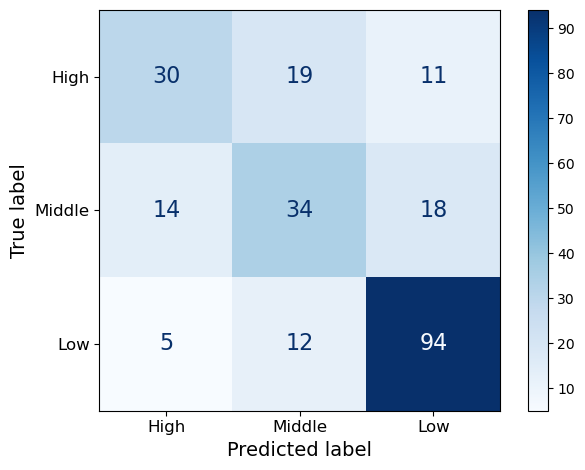

In [81]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    classification_report,
)

y_true = np.asarray(y_true).ravel()
y_pred = np.asarray(y_pred).ravel()
y_proba = np.asarray(y_proba)

# AUC計算用：昇順
auc_class_order = [0, 1, 2]

# 表示用：High → Middle → Low
display_class_order = [2, 1, 0]
display_class_names = ["High", "Middle", "Low"]


# =============================
# 基本指標
# =============================
accuracy = accuracy_score(y_true, y_pred)

balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred,
)

precision_macro = precision_score(
    y_true,
    y_pred,
    labels=auc_class_order,
    average="macro",
    zero_division=0,
)

recall_macro = recall_score(
    y_true,
    y_pred,
    labels=auc_class_order,
    average="macro",
    zero_division=0,
)

f1_macro = f1_score(
    y_true,
    y_pred,
    labels=auc_class_order,
    average="macro",
    zero_division=0,
)

precision_weighted = precision_score(
    y_true,
    y_pred,
    labels=auc_class_order,
    average="weighted",
    zero_division=0,
)

recall_weighted = recall_score(
    y_true,
    y_pred,
    labels=auc_class_order,
    average="weighted",
    zero_division=0,
)

f1_weighted = f1_score(
    y_true,
    y_pred,
    labels=auc_class_order,
    average="weighted",
    zero_division=0,
)

mcc = matthews_corrcoef(
    y_true,
    y_pred,
)


# =============================
# 多クラスROC-AUC
# =============================
# y_probaの列順が [0, 1, 2] である前提
auc_macro_ovr = roc_auc_score(
    y_true,
    y_proba,
    labels=auc_class_order,
    multi_class="ovr",
    average="macro",
)

auc_weighted_ovr = roc_auc_score(
    y_true,
    y_proba,
    labels=auc_class_order,
    multi_class="ovr",
    average="weighted",
)


# =============================
# 結果表示
# =============================
print(f"LOOCV Accuracy:       {accuracy:.4f}")
print(f"Balanced Accuracy:    {balanced_acc:.4f}")
print(f"Macro Precision:      {precision_macro:.4f}")
print(f"Macro Recall:         {recall_macro:.4f}")
print(f"Macro F1 Score:       {f1_macro:.4f}")
print(f"Weighted Precision:   {precision_weighted:.4f}")
print(f"Weighted Recall:      {recall_weighted:.4f}")
print(f"Weighted F1 Score:    {f1_weighted:.4f}")
print(f"MCC:                  {mcc:.4f}")
print(f"Macro OvR ROC-AUC:    {auc_macro_ovr:.4f}")
print(f"Weighted OvR ROC-AUC: {auc_weighted_ovr:.4f}")


# =============================
# クラス別指標
# =============================
print("\nClassification report:")

print(
    classification_report(
        y_true,
        y_pred,
        labels=display_class_order,
        target_names=display_class_names,
        digits=4,
        zero_division=0,
    )
)


# =============================
# 混同行列
# =============================
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=display_class_order,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_class_names,
)

disp.plot(
    cmap="Blues",
    values_format="d",
    text_kw={"fontsize": 16},
)

disp.ax_.set_xlabel(
    "Predicted label",
    fontsize=14,
)

disp.ax_.set_ylabel(
    "True label",
    fontsize=14,
)

disp.ax_.tick_params(
    axis="x",
    labelsize=12,
)

disp.ax_.tick_params(
    axis="y",
    labelsize=12,
)

plt.tight_layout()
plt.show()

In [82]:
import numpy as np
from lightgbm import LGBMClassifier

# =============================
# 特徴量・ターゲット
# =============================
X_train = morgan_fps_data_df
y_train = np.asarray(df_data2).ravel()

z_train = df_data3

X_test_2 = morgan_fps_test_df
y_test_2 = np.asarray(df_test2).ravel()

z_test_2 = df_test3


# =============================
# モデル学習
# =============================
model.fit(X_train, y_train)


# =============================
# 予測
# =============================

# 予測クラス
# 0: Low, 1: Middle, 2: High
y_pred_2 = model.predict(X_test_2)

# 各クラスの予測確率
# shape = (テストサンプル数, 3)
y_proba_2 = model.predict_proba(X_test_2)

print("Model classes:", model.classes_)
print("Prediction shape:", y_pred_2.shape)
print("Probability shape:", y_proba_2.shape)

Model classes: [0 1 2]
Prediction shape: (51,)
Probability shape: (51, 3)


model.classes_: [0 1 2]
y_proba_2 shape: (51, 3)
Test Accuracy:             0.7451
Balanced Accuracy:         0.6625
Macro Precision:           0.7232
Macro Recall:              0.6625
Macro F1 Score:            0.6803
Weighted Precision:        0.7547
Weighted Recall:           0.7451
Weighted F1 Score:         0.7411
MCC:                       0.5526
Macro OvR ROC-AUC:         0.8591
Weighted OvR ROC-AUC:      0.8839
Linear weighted kappa: 0.6211
Quadratic weighted kappa: 0.6903

Classification report:
              precision    recall  f1-score   support

        High     0.8571    0.5455    0.6667        11
      Middle     0.5000    0.5455    0.5217        11
         Low     0.8125    0.8966    0.8525        29

    accuracy                         0.7451        51
   macro avg     0.7232    0.6625    0.6803        51
weighted avg     0.7547    0.7451    0.7411        51



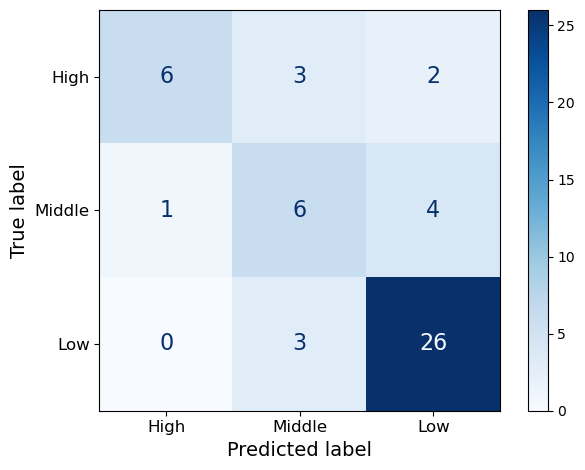

In [83]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
)

# =============================
# 配列形式を統一
# =============================
y_test_2 = np.asarray(y_test_2).ravel()
y_pred_2 = np.asarray(y_pred_2).ravel()
y_proba_2 = np.asarray(y_proba_2)

# クラス定義
# 0 = Low, 1 = Middle, 2 = High
auc_class_order = [0, 1, 2]

# 混同行列・レポートでは High → Middle → Low の順に表示
display_class_order = [2, 1, 0]
display_class_names = ["High", "Middle", "Low"]


# =============================
# 基本指標
# =============================
accuracy = accuracy_score(
    y_test_2,
    y_pred_2,
)

balanced_acc = balanced_accuracy_score(
    y_test_2,
    y_pred_2,
)

precision_macro = precision_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="macro",
    zero_division=0,
)

recall_macro = recall_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="macro",
    zero_division=0,
)

f1_macro = f1_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="macro",
    zero_division=0,
)

precision_weighted = precision_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="weighted",
    zero_division=0,
)

recall_weighted = recall_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="weighted",
    zero_division=0,
)

f1_weighted = f1_score(
    y_test_2,
    y_pred_2,
    labels=auc_class_order,
    average="weighted",
    zero_division=0,
)

# MCCは多クラス分類にも対応
mcc = matthews_corrcoef(
    y_test_2,
    y_pred_2,
)


# =============================
# 多クラスROC-AUC
# =============================
# y_proba_2 の列順が model.classes_ = [0, 1, 2] であることを確認
print("model.classes_:", model.classes_)
print("y_proba_2 shape:", y_proba_2.shape)

auc_macro_ovr = roc_auc_score(
    y_test_2,
    y_proba_2,
    labels=auc_class_order,
    multi_class="ovr",
    average="macro",
)

auc_weighted_ovr = roc_auc_score(
    y_test_2,
    y_proba_2,
    labels=auc_class_order,
    multi_class="ovr",
    average="weighted",
)


# =============================
# 結果表示
# =============================
print(f"Test Accuracy:             {accuracy:.4f}")
print(f"Balanced Accuracy:         {balanced_acc:.4f}")
print(f"Macro Precision:           {precision_macro:.4f}")
print(f"Macro Recall:              {recall_macro:.4f}")
print(f"Macro F1 Score:            {f1_macro:.4f}")
print(f"Weighted Precision:        {precision_weighted:.4f}")
print(f"Weighted Recall:           {recall_weighted:.4f}")
print(f"Weighted F1 Score:         {f1_weighted:.4f}")
print(f"MCC:                       {mcc:.4f}")
print(f"Macro OvR ROC-AUC:         {auc_macro_ovr:.4f}")
print(f"Weighted OvR ROC-AUC:      {auc_weighted_ovr:.4f}")

from sklearn.metrics import cohen_kappa_score

kappa_quadratic = cohen_kappa_score(
    y_test_2,
    y_pred_2,
    weights="quadratic"
)

kappa_linear = cohen_kappa_score(
    y_test_2,
    y_pred_2,
    weights="linear"
)

print(f"Linear weighted kappa: {kappa_linear:.4f}")
print(f"Quadratic weighted kappa: {kappa_quadratic:.4f}")

# =============================
# クラス別評価
# =============================
print("\nClassification report:")

print(
    classification_report(
        y_test_2,
        y_pred_2,
        labels=display_class_order,
        target_names=display_class_names,
        digits=4,
        zero_division=0,
    )
)


# =============================
# 混同行列
# =============================
cm = confusion_matrix(
    y_test_2,
    y_pred_2,
    labels=display_class_order,
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=display_class_names,
)

disp.plot(
    cmap="Blues",
    values_format="d",
    text_kw={"fontsize": 16},
)

disp.ax_.set_xlabel(
    "Predicted label",
    fontsize=14,
)

disp.ax_.set_ylabel(
    "True label",
    fontsize=14,
)

disp.ax_.tick_params(
    axis="x",
    labelsize=12,
)

disp.ax_.tick_params(
    axis="y",
    labelsize=12,
)

plt.tight_layout()
plt.show()

## データ保存部分

In [27]:
from pathlib import Path
import json
import joblib
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


def calculate_classification_metrics(y_true, y_pred):
    """
    多クラス分類用の評価指標を計算する。

    クラス定義:
        0 = Low
        1 = Middle
        2 = High
    """

    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    class_labels = [0, 1, 2]
    class_names = {
        0: "low",
        1: "middle",
        2: "high",
    }

    metrics = {
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_true,
            y_pred,
        ),

        # 各クラスを同じ重みで平均
        "precision_macro": precision_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0,
        ),
        "recall_macro": recall_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0,
        ),
        "f1_macro": f1_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="macro",
            zero_division=0,
        ),

        # クラスのサンプル数で重み付け
        "precision_weighted": precision_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0,
        ),
        "recall_weighted": recall_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0,
        ),
        "f1_weighted": f1_score(
            y_true,
            y_pred,
            labels=class_labels,
            average="weighted",
            zero_division=0,
        ),

        # 多クラス対応MCC
        "mcc": matthews_corrcoef(
            y_true,
            y_pred,
        ),

        # 順序付きクラス向け
        "linear_weighted_kappa": cohen_kappa_score(
            y_true,
            y_pred,
            labels=class_labels,
            weights="linear",
        ),
        "quadratic_weighted_kappa": cohen_kappa_score(
            y_true,
            y_pred,
            labels=class_labels,
            weights="quadratic",
        ),

        # Low=0, Middle=1, High=2として評価
        "ordinal_mae": np.mean(
            np.abs(y_true - y_pred)
        ),
        "within_one_class_accuracy": np.mean(
            np.abs(y_true - y_pred) <= 1
        ),
    }

    # クラス別指標
    precision_each = precision_score(
        y_true,
        y_pred,
        labels=class_labels,
        average=None,
        zero_division=0,
    )

    recall_each = recall_score(
        y_true,
        y_pred,
        labels=class_labels,
        average=None,
        zero_division=0,
    )

    f1_each = f1_score(
        y_true,
        y_pred,
        labels=class_labels,
        average=None,
        zero_division=0,
    )

    for index, class_label in enumerate(class_labels):
        class_name = class_names[class_label]

        metrics[f"precision_{class_name}"] = precision_each[index]
        metrics[f"recall_{class_name}"] = recall_each[index]
        metrics[f"f1_{class_name}"] = f1_each[index]

    # JSON保存できるようPythonのfloatへ変換
    metrics = {
        key: float(value)
        for key, value in metrics.items()
    }

    return metrics

In [28]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
)


def plot_and_save_confusion_matrix(
    y_true,
    y_pred,
    class_order=(2, 1, 0),
    class_names=("High", "Middle", "Low"),
    save_path=None,
    show=False,
):
    """
    多クラス分類用の混同行列を作成・保存する。

    クラス定義
    ----------
    0 : Low
    1 : Middle
    2 : High

    表示順
    ------
    High -> Middle -> Low
    """

    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    if len(class_order) != len(class_names):
        raise ValueError(
            "class_orderとclass_namesの要素数が一致していません。"
        )

    # labels引数で表示順を直接指定するため、
    # 後から行列を並べ替える必要はない
    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=list(class_order),
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=list(class_names),
    )

    disp.plot(
        cmap="Blues",
        values_format="d",
        text_kw={"fontsize": 16},
    )

    disp.ax_.set_xlabel(
        "Predicted label",
        fontsize=14,
    )

    disp.ax_.set_ylabel(
        "True label",
        fontsize=14,
    )

    disp.ax_.tick_params(
        axis="x",
        labelsize=12,
    )

    disp.ax_.tick_params(
        axis="y",
        labelsize=12,
    )

    plt.tight_layout()

    if save_path is not None:
        save_path = str(save_path)

        plt.savefig(
            save_path,
            format="svg",
            bbox_inches="tight",
            dpi=300,
        )

    if show:
        plt.show()
    else:
        plt.close()

    return cm

In [31]:
def _json_converter(obj):
    """
    NumPy型やPathをJSON保存可能な型に変換する。
    """

    if isinstance(obj, np.integer):
        return int(obj)

    if isinstance(obj, np.floating):
        return float(obj)

    if isinstance(obj, np.ndarray):
        return obj.tolist()

    if isinstance(obj, Path):
        return str(obj)

    raise TypeError(
        f"Object of type {type(obj).__name__} "
        "is not JSON serializable"
    )

In [32]:
from pathlib import Path
import json
import joblib
import numpy as np

from sklearn.metrics import confusion_matrix


def save_model_params_metrics_features_and_figures(
    model,
    model_params,
    feature_params,
    save_dir,
    model_name="model",
    y_true_loocv=None,
    y_pred_loocv=None,
    y_true_test=None,
    y_pred_test=None,
    class_order=(2, 1, 0),
    class_names=("High", "Middle", "Low"),
):
    """
    学習済みモデル、モデル条件、特徴量条件、評価指標、
    混同行列図をまとめて保存する。

    クラス定義
    ----------
    0 : Low
    1 : Middle
    2 : High

    Parameters
    ----------
    model:
        学習済みモデル。

    model_params : dict
        モデルのハイパーパラメータ。

    feature_params : dict
        特徴量作成条件。

    save_dir : str or Path
        保存先フォルダ。

    model_name : str
        保存ファイル名のベース。

    y_true_loocv, y_pred_loocv:
        LOOCVの正解ラベルと予測ラベル。

    y_true_test, y_pred_test:
        外部テストの正解ラベルと予測ラベル。

    class_order:
        混同行列の表示順。
        デフォルトは High → Middle → Low。

    class_names:
        class_orderに対応する表示名。
    """

    save_dir = Path(save_dir)
    save_dir.mkdir(parents=True, exist_ok=True)

    class_order = list(class_order)
    class_names = list(class_names)

    if len(class_order) != len(class_names):
        raise ValueError(
            "class_orderとclass_namesの要素数が一致していません。"
        )

    # =============================
    # model保存
    # =============================
    model_path = save_dir / f"{model_name}.pkl"
    joblib.dump(model, model_path)

    # =============================
    # モデルハイパーパラメータ保存
    # =============================
    model_params_path = (
        save_dir / f"{model_name}_model_params.json"
    )

    with open(
        model_params_path,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            model_params,
            f,
            indent=4,
            ensure_ascii=False,
            default=_json_converter,
        )

    # =============================
    # 特徴量作成条件保存
    # =============================
    feature_params_path = (
        save_dir / f"{model_name}_feature_params.json"
    )

    with open(
        feature_params_path,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            feature_params,
            f,
            indent=4,
            ensure_ascii=False,
            default=_json_converter,
        )

    # =============================
    # 評価指標
    # =============================
    all_metrics = {}

    # -----------------------------
    # LOOCV
    # -----------------------------
    if (
        y_true_loocv is not None
        and y_pred_loocv is not None
    ):
        y_true_loocv = np.asarray(
            y_true_loocv
        ).ravel()

        y_pred_loocv = np.asarray(
            y_pred_loocv
        ).ravel()

        loocv_metrics = (
            calculate_classification_metrics(
                y_true_loocv,
                y_pred_loocv,
            )
        )

        cm_loocv = confusion_matrix(
            y_true_loocv,
            y_pred_loocv,
            labels=class_order,
        )

        loocv_metrics[
            "confusion_matrix"
        ] = cm_loocv.tolist()

        loocv_metrics[
            "confusion_matrix_class_order"
        ] = class_order

        loocv_metrics[
            "confusion_matrix_class_names"
        ] = class_names

        all_metrics["LOOCV"] = loocv_metrics

        plot_and_save_confusion_matrix(
            y_true=y_true_loocv,
            y_pred=y_pred_loocv,
            class_order=class_order,
            class_names=class_names,
            save_path=(
                save_dir
                / "LOOCV_confusion_matrix.svg"
            ),
            show=False,
        )

    # -----------------------------
    # 外部テスト
    # -----------------------------
    if (
        y_true_test is not None
        and y_pred_test is not None
    ):
        y_true_test = np.asarray(
            y_true_test
        ).ravel()

        y_pred_test = np.asarray(
            y_pred_test
        ).ravel()

        test_metrics = (
            calculate_classification_metrics(
                y_true_test,
                y_pred_test,
            )
        )

        cm_test = confusion_matrix(
            y_true_test,
            y_pred_test,
            labels=class_order,
        )

        test_metrics[
            "confusion_matrix"
        ] = cm_test.tolist()

        test_metrics[
            "confusion_matrix_class_order"
        ] = class_order

        test_metrics[
            "confusion_matrix_class_names"
        ] = class_names

        all_metrics["Test"] = test_metrics

        plot_and_save_confusion_matrix(
            y_true=y_true_test,
            y_pred=y_pred_test,
            class_order=class_order,
            class_names=class_names,
            save_path=(
                save_dir
                / "test_confusion_matrix.svg"
            ),
            show=False,
        )

    # =============================
    # 評価指標保存
    # =============================
    metrics_path = (
        save_dir / f"{model_name}_metrics.json"
    )

    with open(
        metrics_path,
        "w",
        encoding="utf-8",
    ) as f:
        json.dump(
            all_metrics,
            f,
            indent=4,
            ensure_ascii=False,
            default=_json_converter,
        )

    # =============================
    # 保存結果表示
    # =============================
    print(f"Model saved: {model_path}")
    print(
        f"Model params saved: "
        f"{model_params_path}"
    )
    print(
        f"Feature params saved: "
        f"{feature_params_path}"
    )
    print(f"Metrics saved: {metrics_path}")

    if (
        y_true_loocv is not None
        and y_pred_loocv is not None
    ):
        print(
            "LOOCV confusion matrix saved: "
            f"{save_dir / 'LOOCV_confusion_matrix.svg'}"
        )

    if (
        y_true_test is not None
        and y_pred_test is not None
    ):
        print(
            "Test confusion matrix saved: "
            f"{save_dir / 'test_confusion_matrix.svg'}"
        )

    return {
        "model_path": model_path,
        "model_params_path": model_params_path,
        "feature_params_path": feature_params_path,
        "metrics_path": metrics_path,
        "metrics": all_metrics,
    }

In [41]:
best_params = study.best_trial.params
best_model = model  # 学習済みの最終モデル
feature_params = {
    "fingerprint_type": "Sort&Slice Morgan fingerprint",
    "radius": radius,
    "L": L,
    "use_counts": use_counts,
    "min_df": min_df,
    "max_df_ratio": max_df_ratio,
    "n_selected_raw_ids": len(selected_raw_ids),
}

save_model_params_metrics_features_and_figures(
    model=best_model,
    model_params=best_params,
    feature_params=feature_params,
    save_dir="../output/multi_classification/run_002",
    model_name="best_lgbm",
    y_true_loocv=y_true,
    y_pred_loocv=y_pred,
    y_true_test=y_test_2,
    y_pred_test=y_pred_2,
)

Model saved: ../output/multi_classification/run_002/best_lgbm.pkl
Model params saved: ../output/multi_classification/run_002/best_lgbm_model_params.json
Feature params saved: ../output/multi_classification/run_002/best_lgbm_feature_params.json
Metrics saved: ../output/multi_classification/run_002/best_lgbm_metrics.json
LOOCV confusion matrix saved: ../output/multi_classification/run_002/LOOCV_confusion_matrix.svg
Test confusion matrix saved: ../output/multi_classification/run_002/test_confusion_matrix.svg


{'model_path': PosixPath('../output/multi_classification/run_002/best_lgbm.pkl'),
 'model_params_path': PosixPath('../output/multi_classification/run_002/best_lgbm_model_params.json'),
 'feature_params_path': PosixPath('../output/multi_classification/run_002/best_lgbm_feature_params.json'),
 'metrics_path': PosixPath('../output/multi_classification/run_002/best_lgbm_metrics.json'),
 'metrics': {'LOOCV': {'accuracy': 0.6624472573839663,
   'balanced_accuracy': 0.6125580125580127,
   'precision_macro': 0.6278195721988652,
   'recall_macro': 0.6125580125580127,
   'f1_macro': 0.6162718655527124,
   'precision_weighted': 0.6514566435995931,
   'recall_weighted': 0.6624472573839663,
   'f1_weighted': 0.6531899249428201,
   'mcc': 0.46279314811459804,
   'linear_weighted_kappa': 0.5104838204919573,
   'quadratic_weighted_kappa': 0.5588750764214387,
   'ordinal_mae': 0.4177215189873418,
   'within_one_class_accuracy': 0.919831223628692,
   'precision_low': 0.7480314960629921,
   'recall_low':